In [ ]:
import os
import sys
import pandas as pd
import numpy as np
import os
import h5py
import pydicom 
import glob
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
import pickle
import scipy

sys.path.append('../MARS/preprocess_dicoms')

from read_dicom_functions import GetDicomSlices, GetImageFromDicomSlices, GetImageFromDicomSlices_PixelData, ImageBQML2SUV
from utils import show_mips, show_grid, bbox_nd, read_image_h5, read_header_pkl, get_sample_from_df
import pdb
import time
import argparse
from collections import Counter

import SimpleITK as sitk


In [134]:
def get_imaging_plane(orientation):
    plane = np.cross(orientation[0:3], orientation[3:6])
    plane = [abs(x) for x in plane]

    if plane[0] == 1: #Sagittal
        return 'sagittal'
    elif plane[1] == 1: #Coronal
        return 'coronal'
    elif plane[2] == 1: #Transverse
        return 'transverse'
    else:
        print(f'Plane is not recognized, plane = {plane}')
def load_sitk_from_dir(dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    return image

In [103]:
filenames = {'CT': {}, 'PT': {}}

full_pt = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_curated.csv')
assert full_pt.shape[0] == full_pt['filepath'].nunique(), "Duplicate filepaths in full_pt dataframe"
for idx, row in full_pt.iterrows():
    filenames['PT'][row['filepath']] = row['filename']

full_ct = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_filtered_for_ct_segmentation.csv')
assert full_ct.shape[0] == full_ct['filepath'].nunique(), "Duplicate filepaths in full_ct dataframe"
for idx, row in full_ct.iterrows():
    filenames['CT'][row['filepath']] = row['filename']


In [ ]:
df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')

# take all ids which have a PT and CT scan
ids_with_pt_and_ct = filenames['PT'].keys() & filenames['CT'].keys()

/tmp/ipykernel_2549084/2078214096.py:1: DtypeWarning: Columns (59) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')


On 22290442
/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/22290442/22290442_ct_0
/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/22290442/22290442_pt_0
h5 PT shape: (200, 200, 619), dicom PT shape: (200, 200, 619), resampled CT shape: (200, 200, 619)
On 23601167


KeyboardInterrupt: 

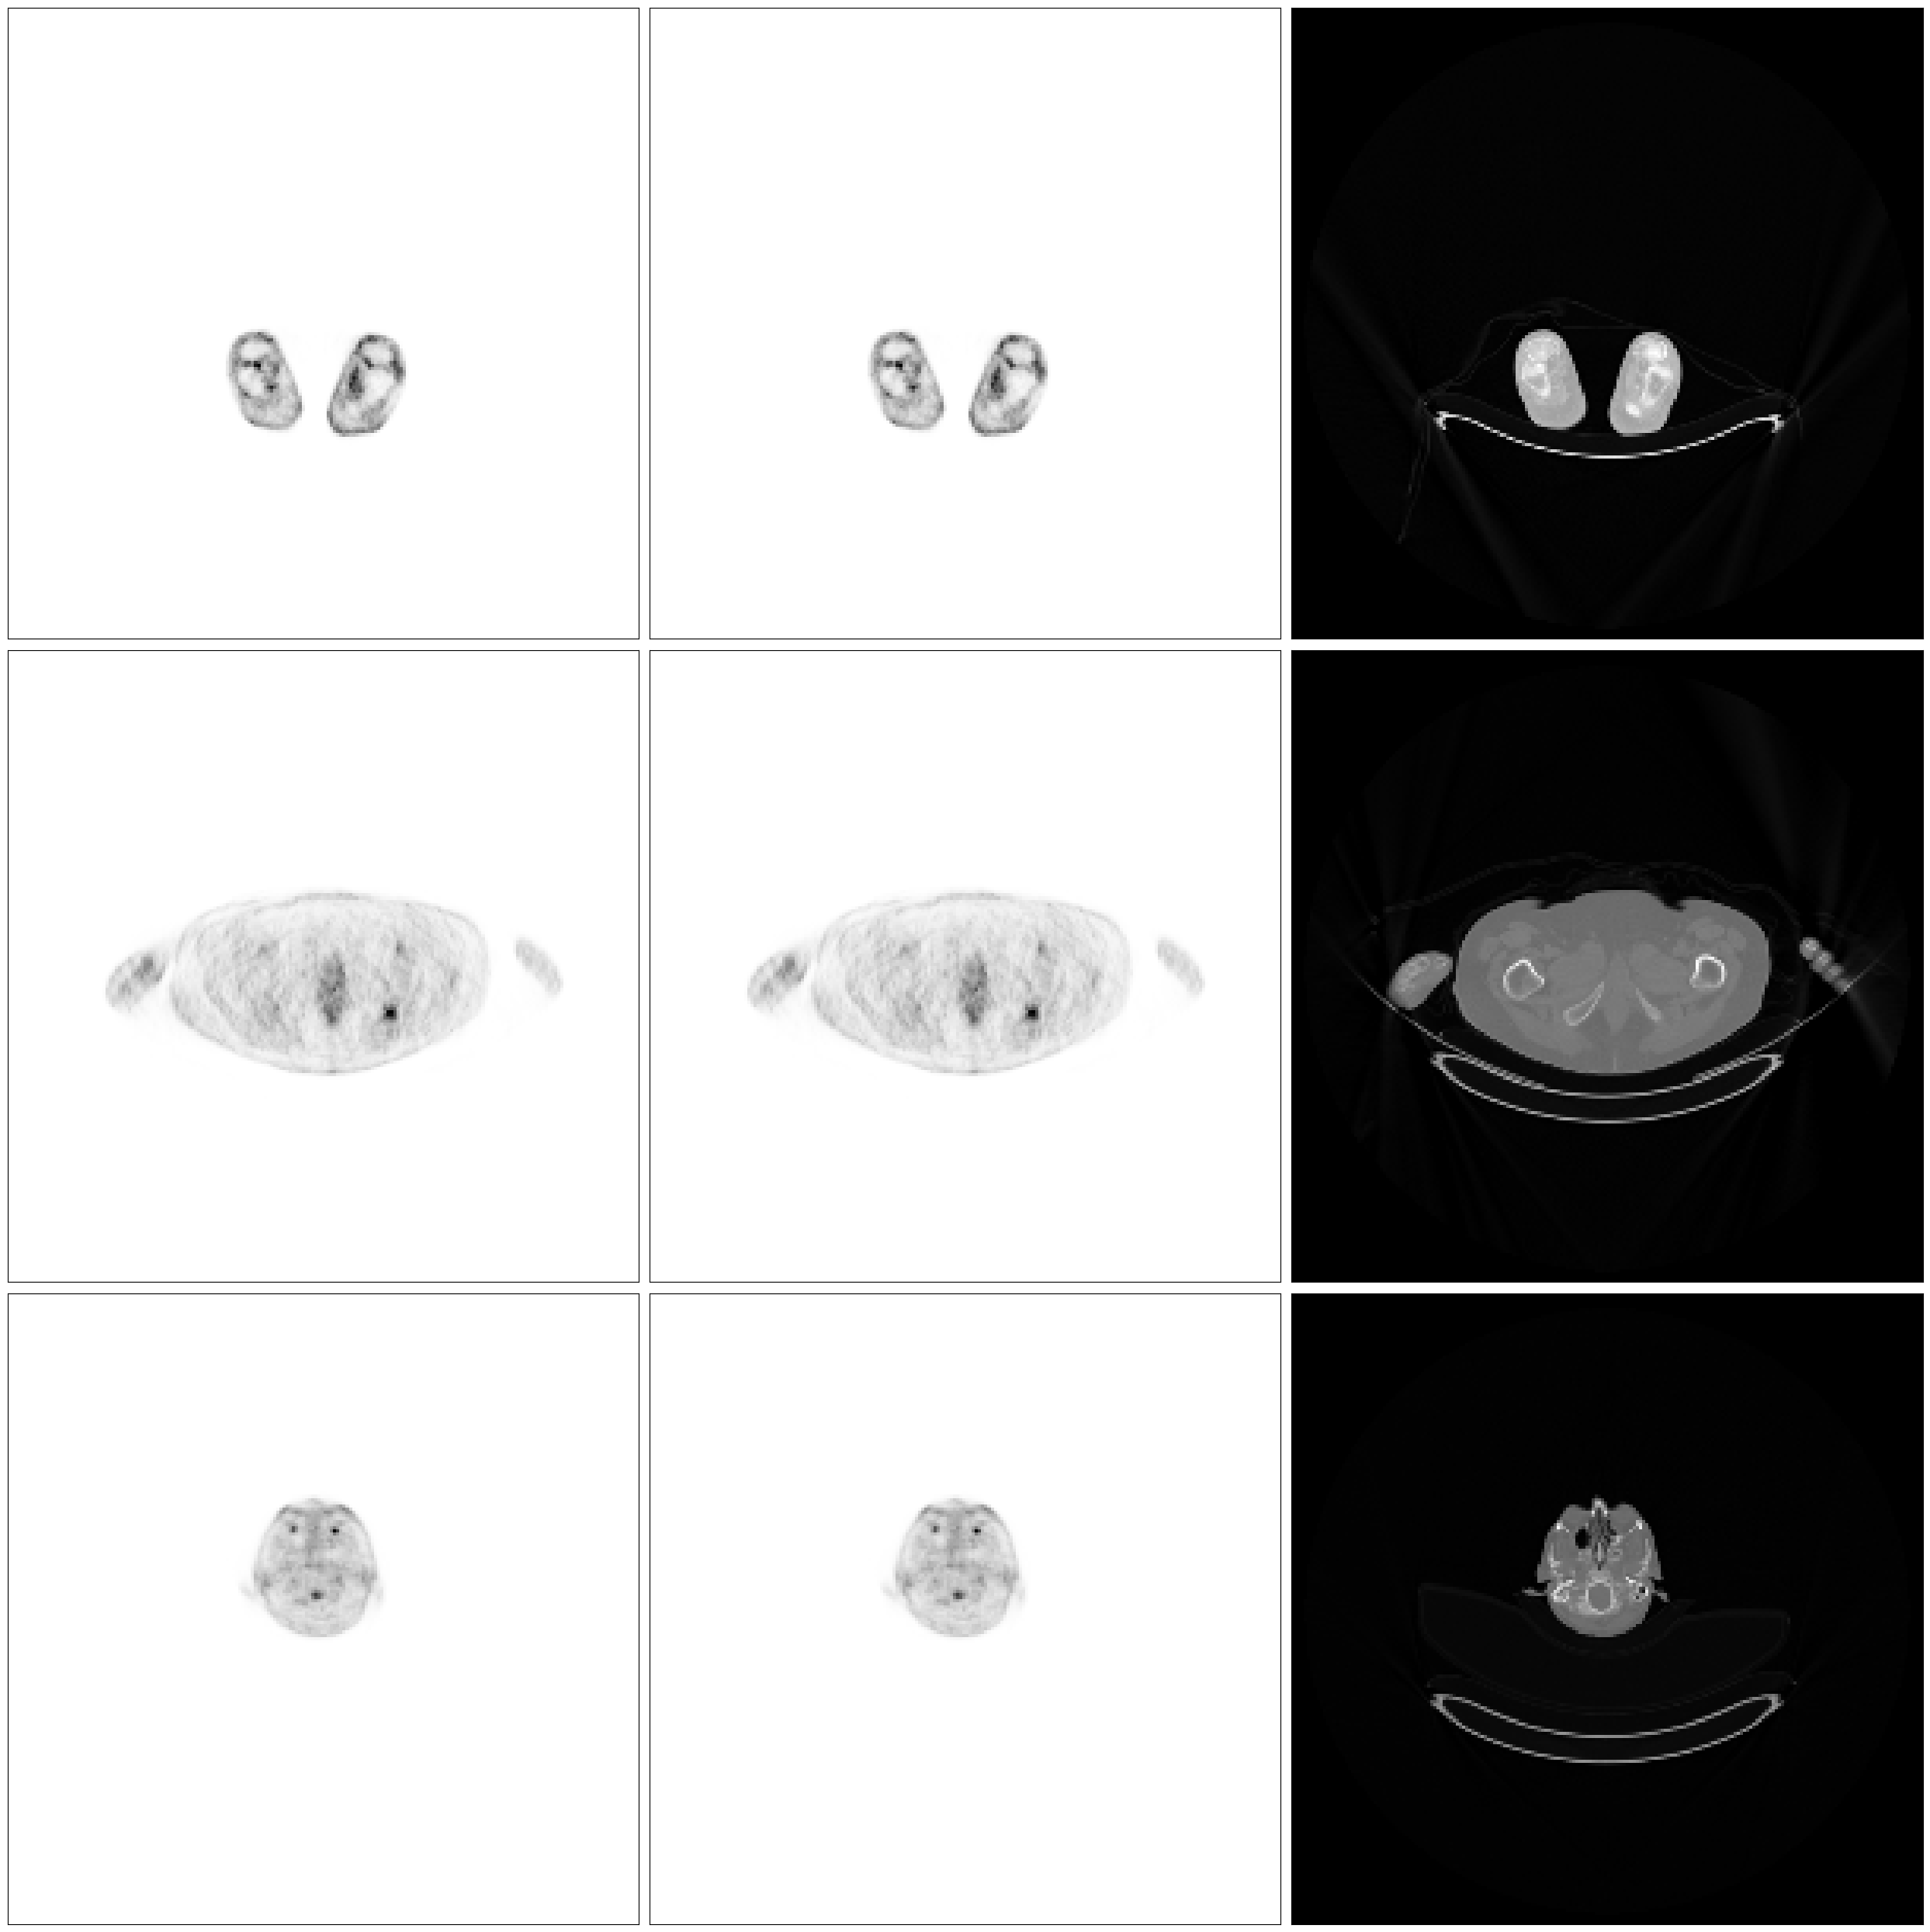

In [158]:
for id in ids_with_pt_and_ct:
    print(f'On {id}')
    output_folder = f'/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5_aligned_ct/{id}'
    qc_output_folder = f'/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/qc_ct_alignment_to_pet/{id}'
    os.makedirs(output_folder, exist_ok=True)
    os.makedirs(qc_output_folder, exist_ok=True)

    SLICES = GetDicomSlices(f'/gpfs/data/mayerhoeferlab/projects/myeloma/dicom/{id}')

    L = np.array([np.array(x.ImageOrientationPatient).size for x in SLICES])
    idx = np.where(L==6)[0]
    SLICES = [SLICES[i] for i in idx]

    # Unique series
    SUID = [x.SeriesInstanceUID for x in SLICES]
    SUID = list(set(SUID))

    # get the unique orientations
    ORIENT = np.round(np.array([x.ImageOrientationPatient for x in SLICES]),decimals=2) 
    ORIENT = np.unique(ORIENT,axis=0)

    # sort the unique SUID's and orientations
    SUID = sorted(SUID)
    ORIENT = ORIENT[np.lexsort((ORIENT[:, 5],ORIENT[:, 4],ORIENT[:, 3],ORIENT[:, 2],ORIENT[:, 1],ORIENT[:, 0]))]

    # for every combination of (SUID, orientation), save all slices with this combination
    dicto_slices_for_suid_orient = {}
    for slic in SLICES:
        key = (slic.SeriesInstanceUID, tuple(np.round(slic.ImageOrientationPatient, decimals=2)))
        if key not in dicto_slices_for_suid_orient:
            dicto_slices_for_suid_orient[key] = []
        dicto_slices_for_suid_orient[key].append(slic)

    dir_path_dict = {'CT': '', 'PT': ''}
    for modality in ['CT', 'PT']:
        subdf = df[(df.filepath == id) & (df.modality == modality)]
        row = subdf[subdf.filename == filenames[modality][id]]
        assert(len(row) == 1), f"Expected exactly one row for filepath {id} and modality {modality}, but got {len(row)}"
        orient_str = row['image_orientation'].values[0]
        orient = np.fromstring(orient_str.strip('[]'), sep=',').astype(float)
        key = (row['series_uid'].values[0], tuple(orient))

        slices_here = dicto_slices_for_suid_orient[key]
        sop_uid = np.array([x.SOPInstanceUID for x in slices_here])
        _,idx = np.unique(sop_uid, return_index=True)
        prev = len(slices_here)
        idx = set(idx)
        slices_here = [x for i,x in enumerate(slices_here) if i in idx]

        # write
        base_path = os.path.join('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite', str(row['filepath'].values[0]), row['filename'].values[0].replace('.h5',''))
        print(base_path)
        dir_path_dict[modality] = base_path
        os.makedirs(base_path, exist_ok=True)
        for i in range(len(slices_here)):
            this_path = os.path.join(base_path, f'slice{i:03d}.dcm')
            slices_here[i].save_as(this_path)

    # now, load as SITK
    img_ct = load_sitk_from_dir(dir_path_dict['CT'])
    img_pt = load_sitk_from_dir(dir_path_dict['PT'])

    # resample CT to PT space
    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(img_pt)          # reference geometry
    resampler.SetInterpolator(sitk.sitkLinear)    # linear for continuous data (MRI/CT), nearest for labels
    resampler.SetDefaultPixelValue(-1024)             # value outside original image
    resampler.SetTransform(sitk.Transform())  # identity
    img_resampled = resampler.Execute(img_ct)

    # write resampled image to folder
    arr_resampled = sitk.GetArrayFromImage(img_resampled)
    arr_resampled = arr_resampled.transpose((1,2,0))
    resampled_path = os.path.join(output_folder, filenames['CT'][id])
    with h5py.File(resampled_path, 'w') as f:
        f.create_dataset('image', data=arr_resampled, compression="gzip")

    # plot QC
    fig, axs = plt.subplots(3,3, figsize=(25,25))

    # axis 0: PT loaded from h5
    # axis 1: PT from dicoms
    # axis 2: resampled CT

    # first, get h5
    file = f'/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/{id}/{filenames["PT"][id]}'
    file = h5py.File(file, 'r')
    image_data = file['image'][:]
    sz_1 = image_data.shape

    # second, PT from dicoms
    arr_pt = sitk.GetArrayFromImage(img_pt)
    arr_pt = arr_pt.transpose((1,2,0))
    sz_2 = arr_pt.shape

    # third, CT from resampled
    arr_resampled = sitk.GetArrayFromImage(img_resampled)
    arr_resampled = arr_resampled.transpose((1,2,0))
    sz_3 = arr_resampled.shape

    candidate_idxs = [sz_1[2]//10, 5*sz_1[2]//10, 9*sz_1[2]//10]
    for ii, img_idx in enumerate(candidate_idxs):
        axs[ii, 0].imshow(image_data[:,:,img_idx], cmap='gray_r')
        axs[ii, 1].imshow(arr_pt[:,:,img_idx], cmap='gray_r')
        axs[ii, 2].imshow(arr_resampled[:,:,img_idx], cmap='gray')
        for jj in range(3):
            axs[ii,jj].xaxis.set_visible(False)
            axs[ii,jj].yaxis.set_visible(False)
    fig.tight_layout()
    fig.savefig(os.path.join(qc_output_folder, 'qc_images.png'))
    print(f'h5 PT shape: {sz_1}, dicom PT shape: {sz_2}, resampled CT shape: {sz_3}')
    print('==========================')

In [138]:
file = f'/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/{id}/{filenames["PT"][id]}'
file

'/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/2938443/2938443_pt_0.h5'

In [ ]:
def load_sitk_from_dir(dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    return image

img_ct = load_sitk_from_dir('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/2938443/2938443_ct_1')
img_pt = load_sitk_from_dir('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/2938443/2938443_pt_0')

In [108]:
print(img_ct.GetSize())
print(img_pt.GetSize())

(512, 512, 331)
(168, 168, 331)


(331, 168, 168)


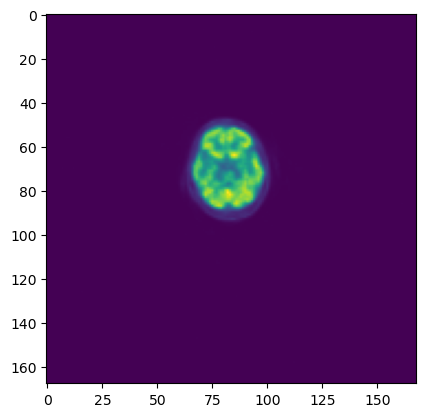

In [109]:
# get numpy array from SITK image "image"
image_array = sitk.GetArrayFromImage(img_pt)
print(image_array.shape)
plt.imshow(image_array[300,:,:])

(168, 168, 331)


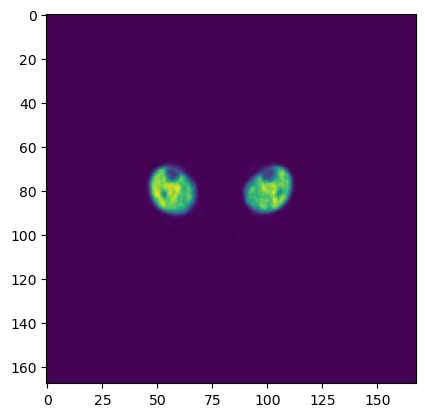

In [129]:
# load h5 as numpy array
file = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/2938443/2938443_pt_0.h5'

file = h5py.File(file, 'r')
image_data = file['image'][:]
print(image_data.shape)
plt.imshow(image_data[:,:,10])

(331, 512, 512)


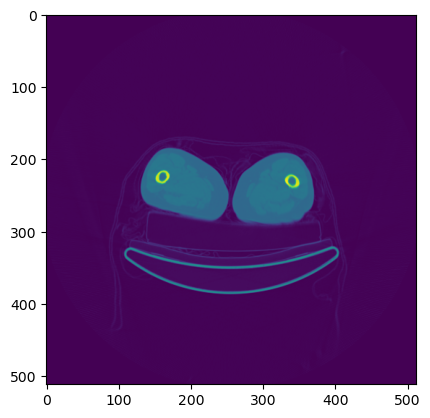

In [ ]:
# get numpy array from SITK image "image"
image_array = sitk.GetArrayFromImage(img_ct)
print(image_array.shape)
plt.imshow(image_array[100,:,:])

In [111]:
# resample CT to PT space
resampler = sitk.ResampleImageFilter()
resampler.SetReferenceImage(img_pt)          # reference geometry
resampler.SetInterpolator(sitk.sitkLinear)    # linear for continuous data (MRI/CT), nearest for labels
resampler.SetDefaultPixelValue(-1024)             # value outside original image
resampler.SetTransform(sitk.Transform())  # identity
img_resampled = resampler.Execute(img_ct)

(168, 168, 331)
(168, 168, 331)


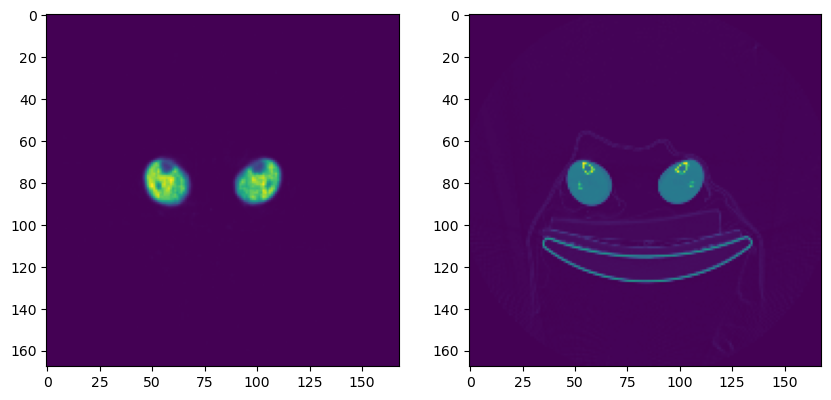

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(10,5))

arr_pt = sitk.GetArrayFromImage(img_pt)
arr_pt = arr_pt.transpose((1,2,0))
arr_resampled = sitk.GetArrayFromImage(img_resampled)
arr_resampled = arr_resampled.transpose((1,2,0))

idx = 10
axs[0].imshow(arr_pt[:,:,idx])
axs[1].imshow(arr_resampled[:,:,idx])

(331, 168, 168)